# IA101 — Notebook 5 — Détecter des structures dans les données

**Durée : 15 minutes** · Objectif visé : **O6** — détecter des structures dans des données non étiquetées

Dans de nombreux projets, les données ne comportent **pas d'étiquette** : dossiers sans diagnostic, appels sans catégorie, mesures sans annotation. L'apprentissage **non supervisé** permet alors de détecter des tendances et des structures :

- le **regroupement** (*clustering*) forme des groupes d'observations similaires ;
- la **réduction de dimension** résume de nombreuses variables en quelques composantes, par exemple pour visualiser les données.

### Plan
1. Le regroupement par k-moyennes
2. Choisir le nombre de groupes
3. L'analyse en composantes principales (ACP)

In [2]:
# @title
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Le regroupement par k-moyennes

L'algorithme des **k-moyennes** cherche k centres et affecte chaque observation au centre le plus proche. Il minimise l'**inertie**, la somme des distances au carré entre chaque observation et son centre :

$$J = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2$$

Il alterne deux étapes jusqu'à convergence :
1. **affectation** : chaque observation rejoint le centre le plus proche ;
2. **mise à jour** : chaque centre devient la moyenne des observations de son groupe.

On reprend les iris **sans utiliser l'espèce** : l'algorithme ne voit que les 4 mesures. Comme pour le KNN, les distances exigent des variables normalisées.

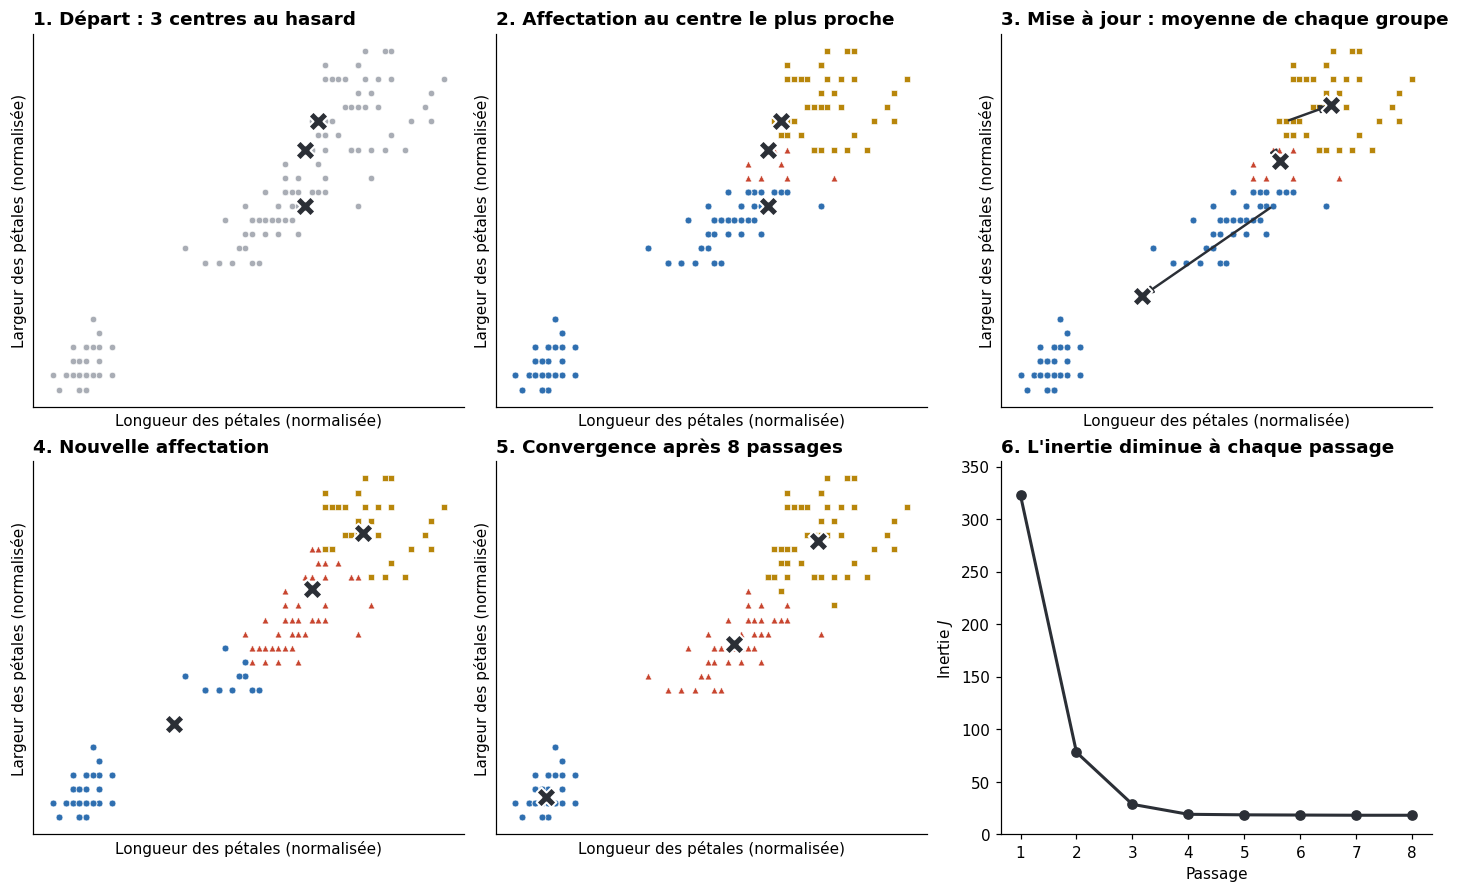

In [4]:
# @title
from sklearn.datasets import load_iris

COULEURS = ["#2f6fb0", "#c8452f", "#b8860b"]
MARQUEURS = ["o", "^", "s"]
GRIS, ENCRE = "#a9adb5", "#2b2f36"

# Deux mesures normalisées, pour pouvoir dessiner l'algorithme dans un plan
iris = load_iris()
X_vue = StandardScaler().fit_transform(iris.data[:, 2:4])  # longueur et largeur des pétales

def affecter(X, centres):
    """Étape d'affectation : chaque observation rejoint le centre le plus proche."""
    distances = np.linalg.norm(X[:, None] - centres, axis=2)
    return distances.argmin(axis=1)

def mettre_a_jour(X, groupes):
    """Étape de mise à jour : chaque centre devient la moyenne de son groupe."""
    return np.array([X[groupes == k].mean(axis=0) for k in range(3)])

def inertie(X, centres, groupes):
    """Somme des distances au carré entre chaque observation et son centre."""
    return ((X - centres[groupes]) ** 2).sum()

# k-moyennes à la main, avec k = 3 et trois observations comme centres de départ
rng = np.random.default_rng(1)
centres = X_vue[rng.choice(len(X_vue), 3, replace=False)]
historique = []
while True:
    groupes = affecter(X_vue, centres)
    nouveaux = mettre_a_jour(X_vue, groupes)
    historique.append((centres, groupes, nouveaux))
    if np.allclose(centres, nouveaux):
        break
    centres = nouveaux
inerties = [inertie(X_vue, c, g) for c, g, _ in historique]

def nuage(ax, groupes=None):
    """Affiche les observations, en gris tant qu'elles n'ont pas de groupe."""
    if groupes is None:
        ax.scatter(*X_vue.T, s=18, color=GRIS, edgecolor="white", linewidth=0.4)
        return
    for k in range(3):
        ax.scatter(*X_vue[groupes == k].T, s=20, color=COULEURS[k], marker=MARQUEURS[k], edgecolor="white", linewidth=0.4)

def marquer(ax, centres):
    """Affiche les centres sous forme de croix."""
    ax.scatter(*centres.T, s=170, marker="X", color=ENCRE, edgecolor="white", linewidth=1.3, zorder=5)

fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
(ax1, ax2, ax3), (ax4, ax5, ax6) = axes

depart, groupes1, centres1 = historique[0]
_, groupes2, centres2 = historique[1]
final, groupes_f, _ = historique[-1]

# 1. Départ : k centres choisis au hasard
nuage(ax1); marquer(ax1, depart)
ax1.set_title("1. Départ : 3 centres au hasard", loc="left", fontweight="bold")

# 2. Affectation
nuage(ax2, groupes1); marquer(ax2, depart)
ax2.set_title("2. Affectation au centre le plus proche", loc="left", fontweight="bold")

# 3. Mise à jour : les flèches montrent le déplacement des centres
nuage(ax3, groupes1); marquer(ax3, centres1)
for ancien, nouveau in zip(depart, centres1):
    ax3.annotate("", xy=nouveau, xytext=ancien, arrowprops=dict(arrowstyle="-|>", color=ENCRE, lw=1.6), zorder=4)
ax3.set_title("3. Mise à jour : moyenne de chaque groupe", loc="left", fontweight="bold")

# 4. Deuxième affectation avec les nouveaux centres
nuage(ax4, groupes2); marquer(ax4, centres1)
ax4.set_title("4. Nouvelle affectation", loc="left", fontweight="bold")

# 5. Convergence : plus aucun changement
nuage(ax5, groupes_f); marquer(ax5, final)
ax5.set_title(f"5. Convergence après {len(historique)} passages", loc="left", fontweight="bold")

for ax in (ax1, ax2, ax3, ax4, ax5):
    ax.set(xticks=[], yticks=[], xlabel="Longueur des pétales (normalisée)", ylabel="Largeur des pétales (normalisée)")

# 6. L'inertie J diminue à chaque passage
passages = np.arange(1, len(inerties) + 1)
ax6.plot(passages, inerties, color=ENCRE, lw=2, marker="o", ms=6)
ax6.set(xlabel="Passage", ylabel="Inertie $J$", xticks=passages, ylim=(0, max(inerties) * 1.1))
ax6.set_title("6. L'inertie diminue à chaque passage", loc="left", fontweight="bold")

plt.show()

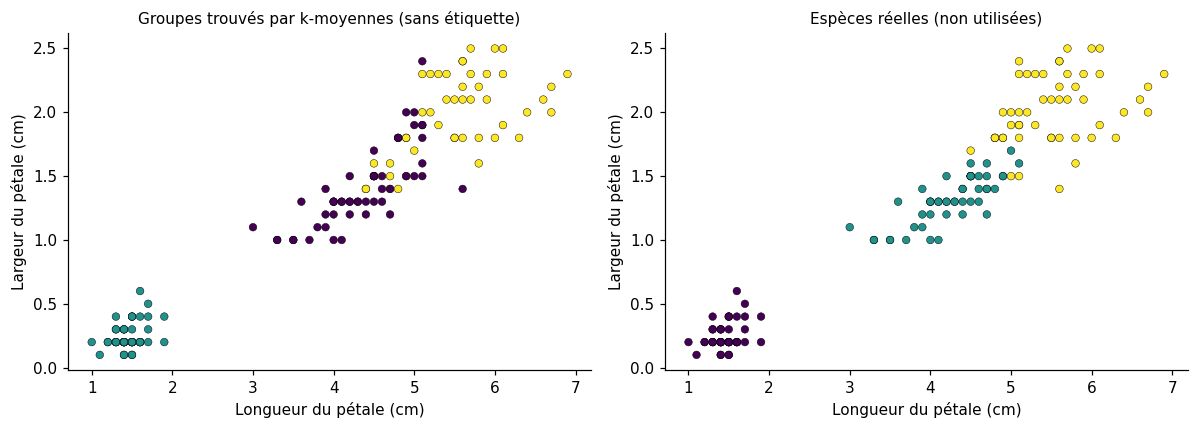

Correspondance entre groupes et espèces :
espèce  setosa  versicolor  virginica
groupe                               
0            0          39         14
1           50           0          0
2            0          11         36


In [5]:
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

kmeans = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_iris)
groupes = kmeans.labels_

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, etiquettes, titre in [(axes[0], groupes, "Groupes trouvés par k-moyennes (sans étiquette)"),
                              (axes[1], iris.target, "Espèces réelles (non utilisées)")]:
    ax.scatter(iris.data[:, 2], iris.data[:, 3], c=etiquettes, cmap="viridis", s=25, edgecolor="k", linewidth=0.3)
    ax.set_xlabel("Longueur du pétale (cm)"); ax.set_ylabel("Largeur du pétale (cm)"); ax.set_title(titre, fontsize=10)
plt.tight_layout(); plt.show()

print("Correspondance entre groupes et espèces :")
print(pd.crosstab(pd.Series(groupes, name="groupe"), pd.Series(iris.target_names[iris.target], name="espèce")))

Sans connaître les espèces, l'algorithme isole parfaitement *setosa* et sépare en grande partie les deux autres espèces. Les numéros de groupes sont arbitraires : seule la partition compte.

L'**indice de Rand ajusté** (ARI) compare deux partitions : 1 signifie un accord parfait, 0 un accord dû au hasard.

Ici les groupes trouvés et les vraies espèces, en corrigeant l'effet du hasard :

$$
\text{ARI} = \frac{\text{RI} - \mathbb{E}[\text{RI}]}{\max(\text{RI}) - \mathbb{E}[\text{RI}]}
$$

où RI est l'indice de Rand, c'est-à-dire la proportion de paires d'observations sur lesquelles les deux partitions sont d'accord (réunies dans les deux ou séparées dans les deux).

À partir du tableau de contingence, la formule devient :

$$
\text{ARI} = \frac{\sum_{i,j} \binom{n_{ij}}{2} - E}{\frac{1}{2}\left[\sum_i \binom{a_i}{2} + \sum_j \binom{b_j}{2}\right] - E}
\qquad \text{avec} \qquad
E = \frac{\sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2}}{\binom{n}{2}}
$$

où :

- $n_{ij}$ : nombre d'observations à la fois dans le groupe $i$ et dans l'espèce $j$
- $a_i$ : taille du groupe $i$
- $b_j$ : taille de l'espèce $j$
- $n$ : nombre total d'observations
- $\binom{m}{2} = \frac{m(m-1)}{2}$ : nombre de paires parmi $m$ observations

L'ARI vaut 1 pour un accord parfait et environ 0 pour un regroupement aléatoire. Il peut être négatif si l'accord est pire que le hasard, et il ne dépend pas des numéros attribués aux groupes.

In [6]:
print(f"Indice de Rand ajusté (groupes vs espèces) : {adjusted_rand_score(iris.target, groupes):.2f}")

Indice de Rand ajusté (groupes vs espèces) : 0.62


## 2. Choisir le nombre de groupes

En pratique, le nombre de groupes est **inconnu**. Deux indicateurs usuels :

- la **méthode du coude** : l'inertie diminue toujours quand k augmente ; on cherche le point où la diminution ralentit nettement ;
- le **coefficient de silhouette** (entre −1 et 1) : il compare, pour chaque observation, la distance moyenne à son groupe et la distance moyenne au groupe voisin le plus proche. Plus il est élevé, mieux les groupes sont séparés.

### Exercice 11 — Calculer l'inertie et la silhouette pour k = 2 à 8

In [ ]:
valeurs_k = range(2, 9)
inerties, silhouettes = [], []
for k in valeurs_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_iris)
    inerties.append(...)        # À COMPLÉTER : attribut inertia_
    silhouettes.append(...)     # À COMPLÉTER : silhouette_score(X_iris, km.labels_)

for k, i, s in zip(valeurs_k, inerties, silhouettes):
    print(f"k = {k} | inertie = {i:7.1f} | silhouette = {s:.3f}")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
valeurs_k = range(2, 9)
inerties, silhouettes = [], []
for k in valeurs_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_iris)
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_iris, km.labels_))

for k, i, s in zip(valeurs_k, inerties, silhouettes):
    print(f"k = {k} | inertie = {i:7.1f} | silhouette = {s:.3f}")
```

</details>

In [ ]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.6))
a.plot(list(valeurs_k), inerties, "o-"); a.set_xlabel("Nombre de groupes k"); a.set_ylabel("Inertie"); a.set_title("Méthode du coude")
b.plot(list(valeurs_k), silhouettes, "o-", color="#1e8449"); b.set_xlabel("Nombre de groupes k"); b.set_ylabel("Silhouette")
b.set_title("Coefficient de silhouette"); plt.tight_layout(); plt.show()

Les indicateurs ne désignent pas toujours la même valeur. Ici, la silhouette est maximale pour k = 2, car *versicolor* et *virginica* se chevauchent. Le choix final de k combine ces indicateurs et la **connaissance du domaine** : un regroupement n'a de valeur que s'il est interprétable.

## 3. L'analyse en composantes principales (ACP)

L'ACP construit de nouvelles variables, les **composantes principales**, qui sont des combinaisons linéaires des variables d'origine, non corrélées entre elles et ordonnées selon la **variance** qu'elles expliquent. Les deux premières composantes offrent souvent une bonne vue d'ensemble de données en grande dimension.

On projette les images de chiffres (64 variables) sur 2 composantes.

Variance expliquée par les 2 premières composantes : 28.5%


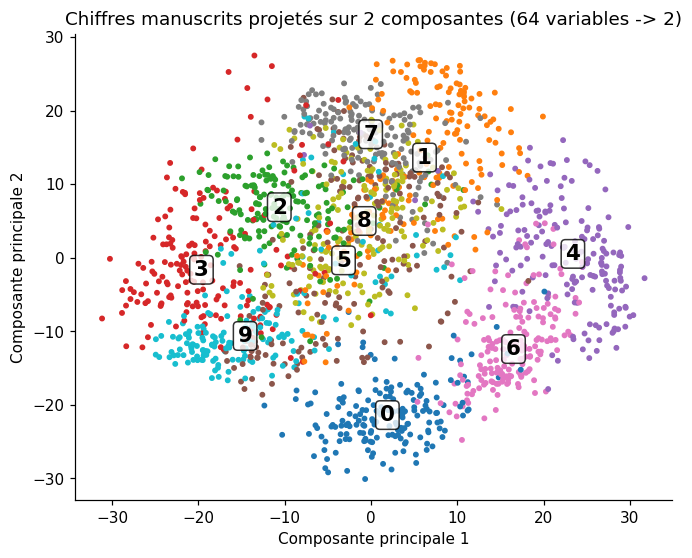

In [9]:
chiffres = load_digits()
acp = PCA(n_components=2).fit(chiffres.data)
projection = acp.transform(chiffres.data)
print(f"Variance expliquée par les 2 premières composantes : {acp.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(7, 5.5))
nuage = plt.scatter(projection[:, 0], projection[:, 1], c=chiffres.target, cmap="tab10", s=8)
for c in range(10):
    cx, cy = np.median(projection[chiffres.target == c], axis=0)
    plt.text(cx, cy, str(c), fontsize=14, fontweight="bold", ha="center", va="center",
             bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8))
plt.xlabel("Composante principale 1"); plt.ylabel("Composante principale 2")
plt.title("Chiffres manuscrits projetés sur 2 composantes (64 variables -> 2)"); plt.show()

Avec seulement 2 composantes sur 64, plusieurs chiffres forment déjà des groupes distincts (0, 4, 6), alors que d'autres se chevauchent (3, 5, 8). La courbe de variance cumulée indique combien de composantes conserver.

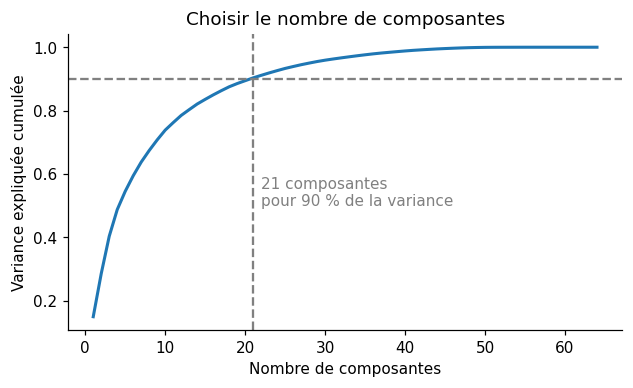

In [10]:
acp_complete = PCA().fit(chiffres.data)
cumul = np.cumsum(acp_complete.explained_variance_ratio_)
n90 = int(np.argmax(cumul >= 0.90)) + 1
plt.figure(figsize=(6.5, 3.5))
plt.plot(range(1, 65), cumul, lw=2); plt.axhline(0.9, color="gray", ls="--"); plt.axvline(n90, color="gray", ls="--")
plt.text(n90 + 1, 0.5, f"{n90} composantes\npour 90 % de la variance", color="gray")
plt.xlabel("Nombre de composantes"); plt.ylabel("Variance expliquée cumulée"); plt.title("Choisir le nombre de composantes"); plt.show()

### Exercice 12 — Visualiser les vins avec l'ACP

Appliquez une normalisation suivie d'une ACP à 2 composantes sur les 13 variables des vins, puis affichez la projection colorée par cultivar. Les cultivars sont-ils séparables ?

In [ ]:
vins = load_wine()
acp_vins = make_pipeline(..., ...)          # À COMPLÉTER : StandardScaler, puis PCA à 2 composantes
proj_vins = acp_vins.fit_transform(vins.data)

plt.figure(figsize=(5.5, 4))
plt.scatter(proj_vins[:, 0], proj_vins[:, 1], c=vins.target, cmap="viridis", edgecolor="k", s=30)
plt.xlabel("Composante 1"); plt.ylabel("Composante 2"); plt.title("Vins projetés sur 2 composantes"); plt.show()

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
vins = load_wine()
acp_vins = make_pipeline(StandardScaler(), PCA(n_components=2))
proj_vins = acp_vins.fit_transform(vins.data)

plt.figure(figsize=(5.5, 4))
plt.scatter(proj_vins[:, 0], proj_vins[:, 1], c=vins.target, cmap="viridis", edgecolor="k", s=30)
plt.xlabel("Composante 1"); plt.ylabel("Composante 2"); plt.title("Vins projetés sur 2 composantes"); plt.show()
print(f"Variance expliquée : {acp_vins[-1].explained_variance_ratio_.sum():.1%}")
```

</details>

In [ ]:
quiz("Quelle est la principale différence entre les k-moyennes et le KNN ?",
     ["Les k-moyennes utilisent des étiquettes connues, le KNN non",
      "Les k-moyennes forment des groupes sans étiquette ; le KNN classe à partir d'exemples étiquetés",
      "Les deux méthodes sont équivalentes"],
     1, "Les k-moyennes sont non supervisées ; le KNN est une méthode de classification supervisée.")

In [ ]:
quiz("Que mesure la variance expliquée d'une composante principale ?",
     ["La proportion de l'information (dispersion) des données qu'elle conserve", "L'exactitude d'un classifieur", "Le nombre de groupes"],
     0, "Les composantes sont ordonnées selon la part de variance totale qu'elles expliquent.")

## À retenir

- L'apprentissage **non supervisé** détecte des structures dans des données **sans étiquette**.
- **k-moyennes** : partition en k groupes qui minimise l'inertie ; variables normalisées ; k se choisit avec l'inertie, la silhouette et la connaissance du domaine.
- **ACP** : nouvelles variables non corrélées, ordonnées par variance expliquée ; utile pour visualiser et compresser.

**Notebook suivant :** 6 — Application intégratrice.